# 02 - Feature engineering and demand forecasting

**Goal:** forecast monthly `demand_tons` for each region for the next quarter (Jan-Mar 2025), and test
honestly how accurate the forecast is.

**Input:** `data/panel_clean.csv`, written by notebook 01.

**Plan**
1. Feature engineering - build the inputs the EDA said matter, and explain why each one is there.
2. Set up the forecast - what is known at the time of forecasting, and what is not.
3. Models - two simple baselines, our regression model, and ARIMAX as a time-series alternative.
4. Backtest - replay 2023-2024 month by month, so the model only ever sees the past.
5. Model checks - coefficients, p-values and residual plots.
6. Final forecast for Q1 2025, with a likely range.

## 1. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.formula.api as smf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.stattools import durbin_watson

warnings.filterwarnings("ignore")          # SARIMAX prints convergence notes we don't need
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
df = pd.read_csv("data/panel_clean.csv", parse_dates=["date"])
df = df.sort_values(["region", "date"]).reset_index(drop=True)
regions = sorted(df["region"].unique())

print("Rows:", len(df), "| regions:", len(regions), "| months:", df["date"].nunique(),
      f"({df['date'].min():%b %Y} - {df['date'].max():%b %Y})")

Rows: 288 | regions: 6 | months: 48 (Jan 2021 - Dec 2024)


## 2. Feature engineering

Every feature comes from a finding in the EDA (notebook 01).

### 2.1 Log transform

**Why:**
- Drivers change demand by a **percentage**, not by a fixed number of tons. A promotion lifts a big region
  and a small region by a similar %. Logs turn % effects into straight lines that a regression can fit.
- With log demand and log price, the price coefficient **is the price elasticity** (% change in demand for a
  1% change in price), which we need for pricing later.
- Demand is right-skewed (a few very large months, mostly from big regions). Logs make it more symmetric.

In [3]:
df["log_demand"] = np.log(df["demand_tons"])
df["log_price"] = np.log(df["price_usd_per_ton"])
df["log_comp_price"] = np.log(df["competitor_price_usd_per_ton"])
df["log_index"] = np.log(df["industrial_index"])

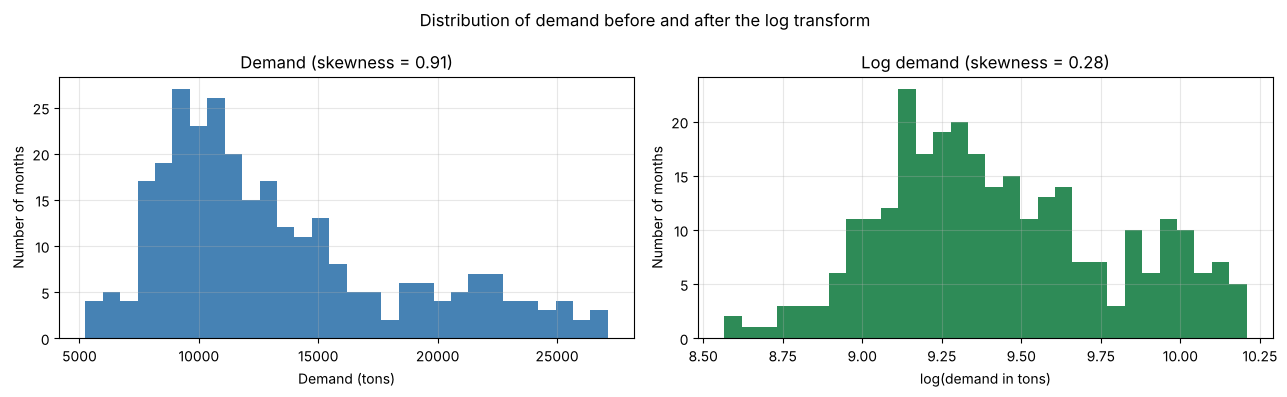

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(df["demand_tons"], bins=30, color="steelblue")
axes[0].set_title(f"Demand (skewness = {stats.skew(df['demand_tons']):.2f})")
axes[0].set_xlabel("Demand (tons)")
axes[0].set_ylabel("Number of months")

axes[1].hist(df["log_demand"], bins=30, color="seagreen")
axes[1].set_title(f"Log demand (skewness = {stats.skew(df['log_demand']):.2f})")
axes[1].set_xlabel("log(demand in tons)")
axes[1].set_ylabel("Number of months")

fig.suptitle("Distribution of demand before and after the log transform")
plt.tight_layout()
plt.show()

**What we see:** raw demand is clearly right-skewed (skewness 0.91), with a long tail of large months that come mostly from Gulf Coast and Southeast. After the log transform the skewness drops to 0.28, much closer to symmetric.

**So what:** the model works on `log_demand`. Its coefficients read as % effects, and the price coefficient is the elasticity.

### 2.2 Seasonality features

**Why:** the EDA showed the same yearly pattern in every region (high Jan-May, low Jul-Nov).
- `month` (1-12) is used as a **category** in the regression: one effect per calendar month, shared by all regions.
- `sin_month` / `cos_month` describe the same yearly wave with only **2 numbers**. They are used in ARIMAX,
  which is fitted per region on only 24-47 months, too few for 11 month effects.

In [5]:
df["month"] = df["date"].dt.month
df["sin_month"] = np.sin(2 * np.pi * df["month"] / 12)
df["cos_month"] = np.cos(2 * np.pi * df["month"] / 12)

### 2.3 Lag features (for the baselines)

**Why:** demand is persistent (lag-1 autocorrelation 0.5-0.8 in the EDA) and seasonal. Last month's demand and
the same month last year are therefore the two natural "simple guesses" every model must beat.
Lags are calculated **within each region**, so one region's value never leaks into another's.

In [6]:
df["demand_lag1"] = df.groupby("region")["demand_tons"].shift(1)
df["demand_lag12"] = df.groupby("region")["demand_tons"].shift(12)

df[["date", "region", "demand_tons", "demand_lag1", "demand_lag12"]].iloc[10:15]

,date,region,demand_tons,demand_lag1,demand_lag12
10,2021-11-01,Great Lakes,"8,387.90","9,154.10",NaN
11,2021-12-01,Great Lakes,"9,032.50","8,387.90",NaN
12,2022-01-01,Great Lakes,"10,522.30","9,032.50","8,574.70"
13,2022-02-01,Great Lakes,"10,451.80","10,522.30","10,887.70"
14,2022-03-01,Great Lakes,"11,117.90","10,451.80","12,323.20"


### 2.4 Time trend or industrial index?

**Why this check:** demand grew over time. We could add a time counter (`t` = months since Jan 2021), but the
EDA suggested the economy explains the growth. If the two move together, the model cannot tell them apart
(**multicollinearity**), so we should keep only one.

In [7]:
df["t"] = (df["date"].dt.year - 2021) * 12 + df["month"] - 1

print(f"Correlation between time trend and industrial index: {df['t'].corr(df['industrial_index']):.2f}")

Correlation between time trend and industrial index: 0.90


**What we see:** the time trend and the industrial index have a correlation of **0.90**. They tell almost the same story.

**Decision:** use only the **industrial index**. It has a business meaning ("the economy grew"), and putting both in the model would make their coefficients unstable. A time trend would also simply extrapolate growth forever, while the index ties growth to a real driver.

### 2.5 Final feature list

| Feature | Type | Used in | Why |
|---|---|---|---|
| `log_price` | number | regression, ARIMAX | own price effect (= elasticity) |
| `promo_flag` | 0/1 | regression, ARIMAX | promotions lift demand |
| `log_comp_price` | number | regression, ARIMAX | competitor pricing |
| `log_index` | number | regression, ARIMAX | economy - explains the growth |
| `region` | category | regression | each region has its own size (region fixed effect) |
| `month` | category | regression | seasonality |
| `sin_month`, `cos_month` | number | ARIMAX | seasonality with only 2 parameters |
| `demand_lag1`, `demand_lag12` | number | baselines | simple guesses to beat |

In [8]:
features = ["log_demand", "log_price", "promo_flag", "log_comp_price", "log_index",
            "region", "month", "sin_month", "cos_month", "demand_lag1", "demand_lag12"]
df[["date"] + features].tail()

,date,log_demand,log_price,promo_flag,log_comp_price,log_index,region,month,sin_month,cos_month,demand_lag1,demand_lag12
283,2024-08-01,9.54,6.85,1,7.02,4.69,West,8,-0.87,-0.50,"13,005.50","10,837.60"
284,2024-09-01,9.24,6.92,0,7.03,4.67,West,9,-1.00,-0.00,"13,939.90","11,397.50"
285,2024-10-01,9.23,6.96,0,7.06,4.69,West,10,-0.87,0.50,"10,302.90","10,739.60"
286,2024-11-01,9.02,7.00,0,7.06,4.69,West,11,-0.50,0.87,"10,248.00","11,217.80"
287,2024-12-01,9.16,7.02,0,7.06,4.70,West,12,-0.00,1.00,"8,269.40","14,681.20"


## 3. Forecast setup

We want to forecast **1, 2 and 3 months ahead** (one quarter). At the moment we make a forecast:

| Input | Known? | What we use |
|---|---|---|
| Our price and promotions in the target month | **Yes** - we decide them | the planned values |
| Competitor price in the target month | No | its last known value |
| Industrial index in the target month | No | its last known value |
| Demand up to today | Yes | used for training |

So this is a **conditional forecast**: "if we charge this price, demand will be about this much". That is exactly
what the pricing step needs.

**Honest testing (backtest):** we stand at the end of each month from Dec 2022 to Nov 2024, train only on data up
to that month, forecast the next 1-3 months, and compare with what really happened. No future data is ever used.

In [9]:
def future_rows(data, origin):
    """The 1-3 months after `origin`, with only the information we would have at `origin`."""
    known = data[data["date"] == origin].set_index("region")
    rows = data[(data["date"] > origin) & (data["date"] <= origin + pd.DateOffset(months=3))].copy()

    rows["horizon"] = (rows["date"].dt.year - origin.year) * 12 + rows["date"].dt.month - origin.month

    # not known in advance -> hold at last known value
    rows["log_comp_price"] = rows["region"].map(known["log_comp_price"])
    rows["log_index"] = rows["region"].map(known["log_index"])
    return rows

## 4. Models

**Baselines**
- **Same as last month:** forecast = demand in the last known month.
- **Same month last year:** forecast = demand in the same month one year earlier.

**Regression (our model):** one model for all regions together, fitted on log demand:

`log(demand) = region effect + month effect + b1*log(price) + b2*promo + b3*log(competitor price) + b4*log(index)`

Fitting all regions together gives 288 rows instead of 48 per region, and the price effect is shared.

**ARIMAX (time-series alternative):** one model per region with the same drivers plus AR(1) errors, i.e.
it also uses last month's surprise. Seasonality enters as `sin_month` / `cos_month`.

In [10]:
FORMULA = "log_demand ~ log_price + promo_flag + log_comp_price + log_index + C(region) + C(month)"


def regression_forecast(history, future):
    model = smf.ols(FORMULA, data=history).fit()
    # exp() of a log forecast slightly underestimates the average, so we correct with
    # the average of exp(residuals) ("smearing" correction)
    correction = np.mean(np.exp(model.resid))
    return np.exp(model.predict(future)) * correction


ARIMAX_INPUTS = ["log_price", "promo_flag", "log_comp_price", "log_index", "sin_month", "cos_month"]


def arimax_forecast(history, future):
    forecast = pd.Series(index=future.index, dtype=float)
    for region in regions:
        past = history[history["region"] == region]
        ahead = future[future["region"] == region]
        model = SARIMAX(past["log_demand"].values, exog=past[ARIMAX_INPUTS].values,
                        order=(1, 0, 0), trend="c").fit(disp=False)
        result = model.get_forecast(len(ahead), exog=ahead[ARIMAX_INPUTS].values)
        # same idea as the smearing correction: mean of a log-normal = exp(mean + variance / 2)
        forecast[ahead.index] = np.exp(result.predicted_mean + result.var_pred_mean / 2)
    return forecast

## 5. Backtest: replay 2023-2024

In [11]:
origins = pd.date_range("2022-12-01", "2024-11-01", freq="MS")
results = []

for origin in origins:
    history = df[df["date"] <= origin]           # only the past
    future = future_rows(df, origin)
    last_month = history[history["date"] == origin].set_index("region")["demand_tons"]

    out = future[["date", "region", "horizon", "demand_tons"]].copy()
    out["origin"] = origin
    out["Same as last month"] = future["region"].map(last_month)
    out["Same month last year"] = future["demand_lag12"]
    out["Regression"] = regression_forecast(history, future)
    out["ARIMAX"] = arimax_forecast(history, future)
    results.append(out)

backtest = pd.concat(results, ignore_index=True)
models = ["Regression", "ARIMAX", "Same as last month", "Same month last year"]

print("Forecasts per model:", len(backtest), "(24 origins x 6 regions x up to 3 months ahead)")
backtest.head()

Forecasts per model: 414 (24 origins x 6 regions x up to 3 months ahead)


,date,region,horizon,demand_tons,origin,Same as last month,Same month last year,Regression,ARIMAX
0,2023-01-01,Great Lakes,1,"9,914.80",2022-12-01,"10,321.70","10,522.30","8,948.96","9,623.64"
1,2023-02-01,Great Lakes,2,"10,536.90",2022-12-01,"10,321.70","10,451.80","10,156.63","10,389.91"
2,2023-03-01,Great Lakes,3,"10,582.20",2022-12-01,"10,321.70","11,117.90","9,717.95","9,714.65"
3,2023-01-01,Gulf Coast,1,"24,518.40",2022-12-01,"21,571.00","21,679.40","22,813.99","23,048.09"
4,2023-02-01,Gulf Coast,2,"23,443.80",2022-12-01,"21,571.00","20,875.90","23,386.64","23,588.12"


### 5.1 Error metric: WAPE

**WAPE** (weighted absolute percentage error) = total absolute error / total actual demand x 100.

**Why WAPE and not MAPE or RMSE:**
- It reads as "we miss X% of the volume", which business people understand.
- Unlike MAPE, it does not blow up in small months.
- It gives big regions more weight, as the business does (a 10% miss in Gulf Coast costs more tons than in Northeast).

We also report **bias** (total error / total actual): negative = we forecast too low on average.

In [12]:
def wape(actual, forecast):
    return np.sum(np.abs(forecast - actual)) / np.sum(actual) * 100


def bias(actual, forecast):
    return np.sum(forecast - actual) / np.sum(actual) * 100


scores = []
for m in models:
    row = {"Model": m,
           "WAPE (%)": wape(backtest["demand_tons"], backtest[m]),
           "Bias (%)": bias(backtest["demand_tons"], backtest[m])}
    for h in [1, 2, 3]:
        d = backtest[backtest["horizon"] == h]
        row[f"WAPE {h} month ahead (%)"] = wape(d["demand_tons"], d[m])
    scores.append(row)

scores = pd.DataFrame(scores).sort_values("WAPE (%)").reset_index(drop=True)
scores.round(1)

,Model,WAPE (%),Bias (%),WAPE 1 month ahead (%),WAPE 2 month ahead (%),WAPE 3 month ahead (%)
0,Regression,5.10,-0.80,4.80,5.30,5.40
1,ARIMAX,7.40,2.00,6.40,7.80,8.20
2,Same as last month,11.40,-0.10,8.80,11.60,14.00
3,Same month last year,13.80,-8.30,14.00,13.70,13.70


In [13]:
by_region = pd.DataFrame({
    m: [wape(backtest.loc[backtest["region"] == r, "demand_tons"], backtest.loc[backtest["region"] == r, m])
        for r in regions]
    for m in models
}, index=regions)
by_region.index.name = "WAPE (%) by region"
by_region.round(1)

,Regression,ARIMAX,Same as last month,Same month last year
WAPE (%) by region,,,,
Great Lakes,5.20,7.30,13.00,11.60
Gulf Coast,5.00,7.40,7.70,8.90
Midwest,4.90,6.20,9.90,19.80
Northeast,5.20,6.70,10.60,17.60
Southeast,5.30,7.70,12.30,11.10
West,5.30,9.00,17.30,18.50


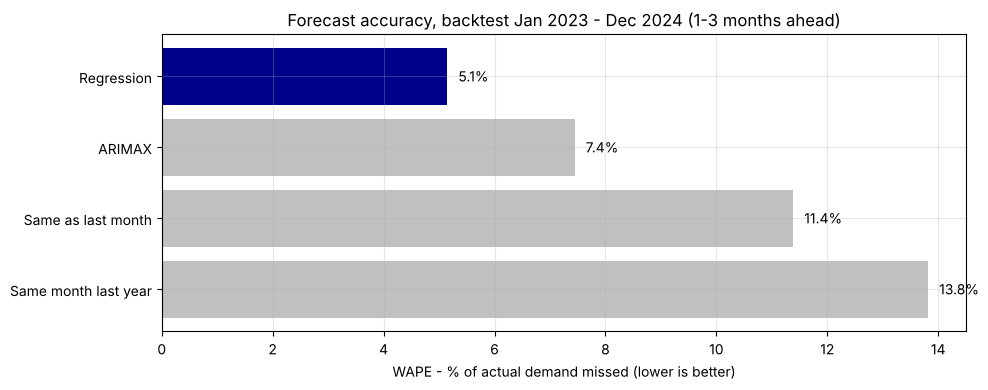

In [14]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ["darkblue" if m == "Regression" else "silver" for m in scores["Model"]]
ax.barh(scores["Model"], scores["WAPE (%)"], color=colors)
for i, value in enumerate(scores["WAPE (%)"]):
    ax.text(value + 0.2, i, f"{value:.1f}%", va="center")
ax.invert_yaxis()
ax.set_xlabel("WAPE - % of actual demand missed (lower is better)")
ax.set_title("Forecast accuracy, backtest Jan 2023 - Dec 2024 (1-3 months ahead)")
plt.tight_layout()
plt.show()

**What we see**
- **Regression is clearly the best: 5.1% WAPE**, less than half the error of "same as last month" (11.4%).
- It stays steady as we look further ahead: 4.8% at 1 month, 5.3% at 2 months, 5.4% at 3 months. The simple baselines get worse quickly (8.8% to 14.0%).
- It is the best model in **every region** (4.9-5.3%), so no region is badly served.
- **ARIMAX (7.4%)** beats the baselines but loses to the regression in every region. Each ARIMAX model sees only one region's 24-47 months, while the regression learns the price, promo and economy effects from all 288 rows at once.
- **"Same month last year"** is worst (13.8%) and forecasts 8.3% too low on average (bias), because it ignores growth.
- Regression bias is only -0.8%: almost no systematic over- or under-forecasting.

**Decision:** use the regression. It is simpler, more accurate and easier to explain than ARIMAX.

### 5.2 Actual vs forecast

1-month-ahead forecasts from the backtest against what really happened.

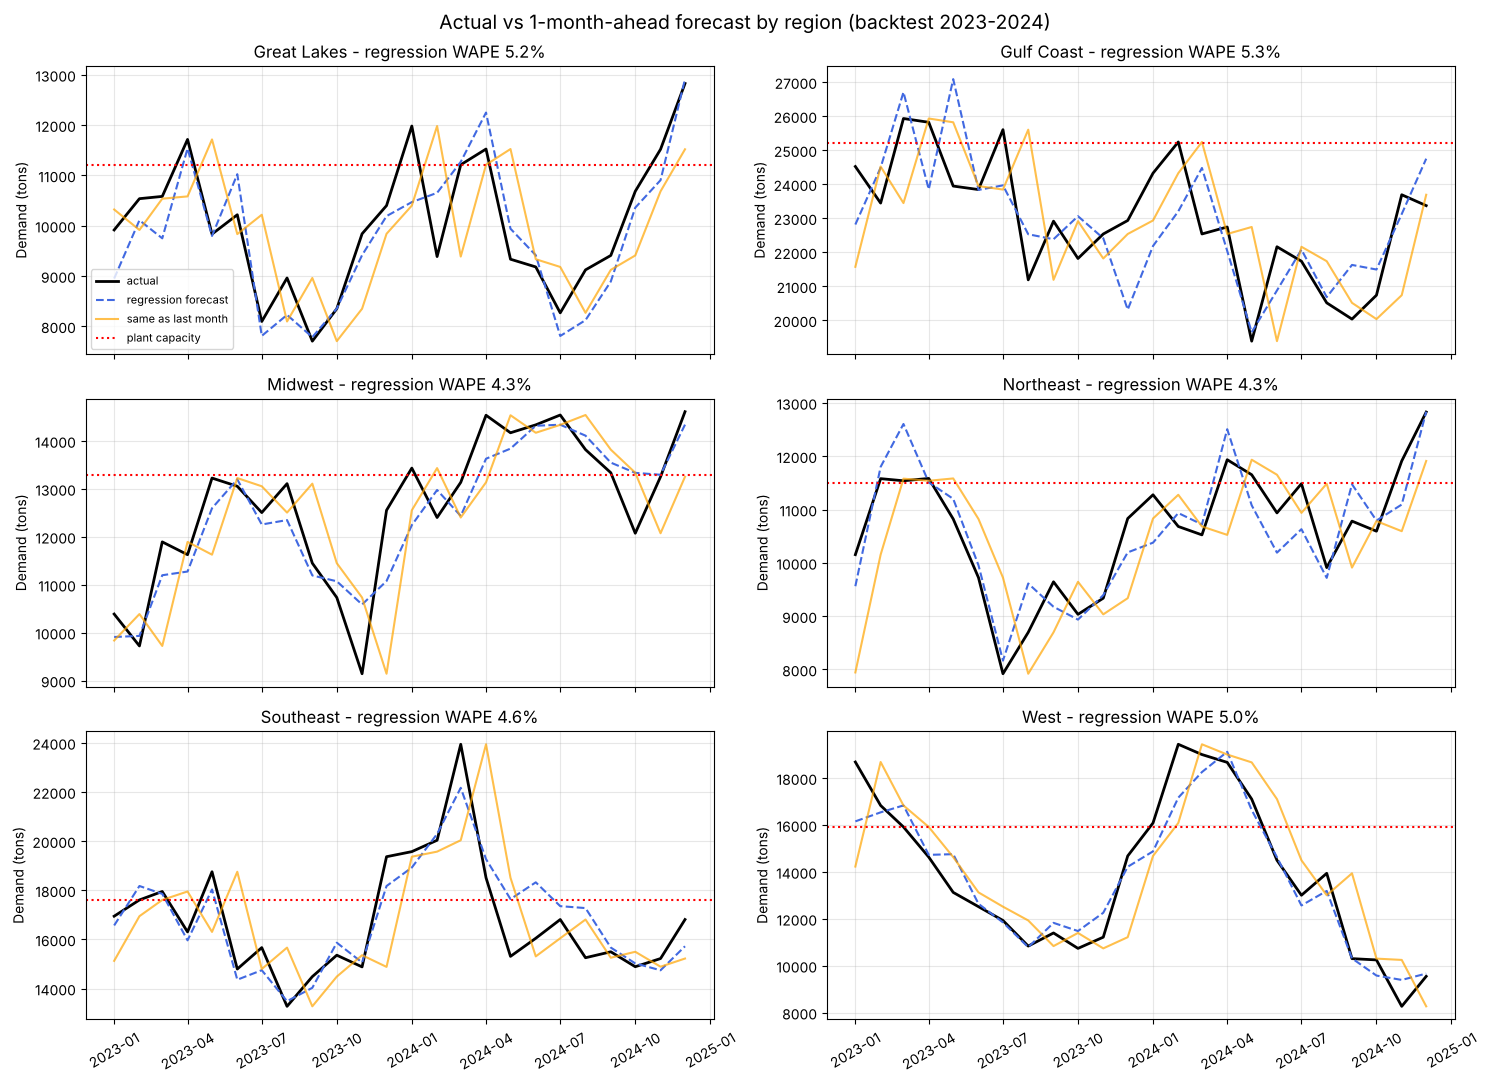

In [15]:
one_ahead = backtest[backtest["horizon"] == 1]

fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
for ax, region in zip(axes.flat, regions):
    d = one_ahead[one_ahead["region"] == region].sort_values("date")
    ax.plot(d["date"], d["demand_tons"], color="black", linewidth=2, label="actual")
    ax.plot(d["date"], d["Regression"], color="royalblue", linestyle="--", label="regression forecast")
    ax.plot(d["date"], d["Same as last month"], color="orange", alpha=0.7, label="same as last month")
    ax.axhline(df.loc[df["region"] == region, "monthly_capacity_tons"].iloc[0],
               color="red", linestyle=":", label="plant capacity")
    ax.set_title(f"{region} - regression WAPE {wape(d['demand_tons'], d['Regression']):.1f}%")
    ax.set_ylabel("Demand (tons)")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Actual vs 1-month-ahead forecast by region (backtest 2023-2024)", fontsize=14)
plt.tight_layout()
plt.show()

**What we see**
- The blue dashed regression forecast follows the black actual line closely in every region, including the turning points: Southeast's spike in March 2024, West's rise and fall in 2024, and the 2023 seasonal dip in Great Lakes.
- "Same as last month" (orange) is always one month late at every turning point. That is why its error is more than twice as large.
- Most of the regression's remaining misses are single unusual months (e.g. Midwest Nov 2023, Great Lakes Feb 2024) that none of the drivers explain.

**Caveat:** the forecast uses our **planned** price for the target month. That is fair, because we set prices. If the price plan changes, the forecast should be rerun with the new prices.

## 6. Model checks

The regression fitted on all 48 months. First the coefficients, then the usual checks on the residuals
(the part of demand the model does not explain).

In [16]:
final_model = smf.ols(FORMULA, data=df).fit()

drivers = ["log_price", "promo_flag", "log_comp_price", "log_index"]
coef_table = pd.DataFrame({
    "coefficient": final_model.params[drivers],
    "95% CI low": final_model.conf_int().loc[drivers, 0],
    "95% CI high": final_model.conf_int().loc[drivers, 1],
    "p-value": final_model.pvalues[drivers],
})
print(f"R-squared: {final_model.rsquared:.3f}   |   rows: {int(final_model.nobs)}")
coef_table.round(3)

R-squared: 0.982   |   rows: 288


,coefficient,95% CI low,95% CI high,p-value
log_price,-2.06,-2.16,-1.97,0.00
promo_flag,0.08,0.06,0.09,0.00
log_comp_price,0.48,0.38,0.58,0.00
log_index,1.51,1.29,1.73,0.00


**What we see:** all four drivers are clearly significant (p < 0.001), and R-squared is 0.98.

| Driver | Coefficient | Meaning |
|---|---|---|
| Our price | **-2.06** (95% CI -2.16 to -1.97) | +1% price -> about **-2.1%** demand |
| Promotion | +0.08 | a promotion month has about **+8%** demand |
| Competitor price | +0.48 | competitor +1% -> our demand about **+0.5%** |
| Industrial index | +1.51 | economy +1% -> demand about **+1.5%** |

All signs make business sense. The price coefficient (-2.06) is the **price elasticity**; notebook 03 checks it in depth.

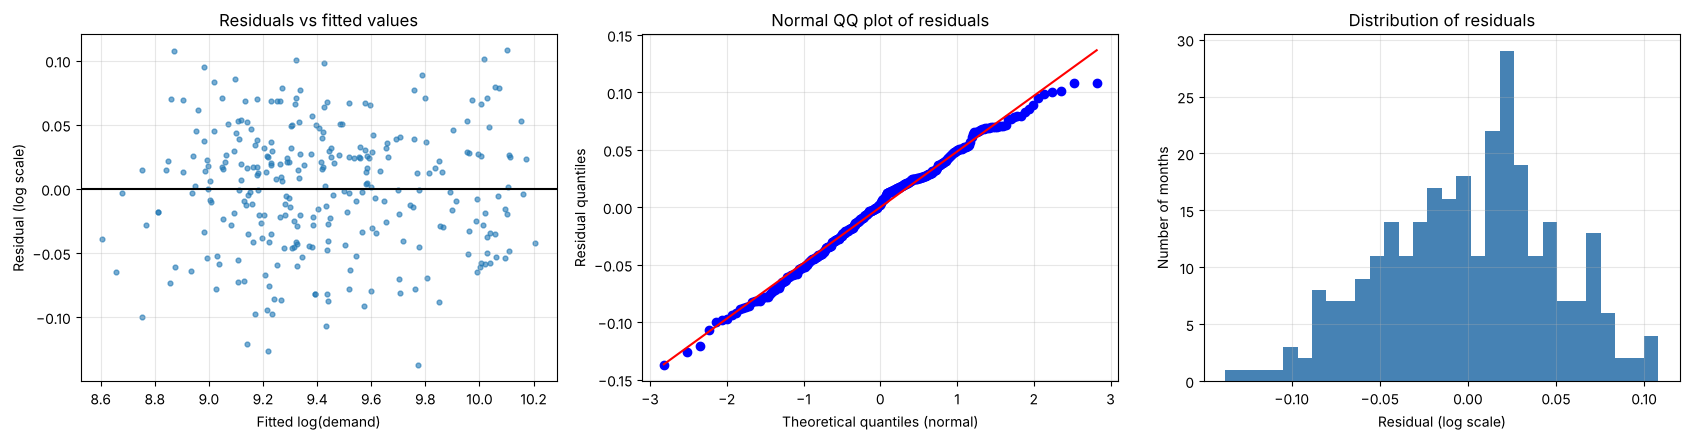

Durbin-Watson by region (about 2 = no autocorrelation left):
  Great Lakes  1.61
  Gulf Coast   1.81
  Midwest      2.10
  Northeast    1.98
  Southeast    1.76
  West         1.86
Shapiro-Wilk normality test p-value: 0.086


In [17]:
residuals = final_model.resid
fitted = final_model.fittedvalues

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].scatter(fitted, residuals, s=12, alpha=0.6)
axes[0].axhline(0, color="black")
axes[0].set_title("Residuals vs fitted values")
axes[0].set_xlabel("Fitted log(demand)")
axes[0].set_ylabel("Residual (log scale)")

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ plot of residuals")
axes[1].set_xlabel("Theoretical quantiles (normal)")
axes[1].set_ylabel("Residual quantiles")

axes[2].hist(residuals, bins=30, color="steelblue")
axes[2].set_title("Distribution of residuals")
axes[2].set_xlabel("Residual (log scale)")
axes[2].set_ylabel("Number of months")

plt.tight_layout()
plt.show()

# Durbin-Watson inside each region: about 2 = no autocorrelation left over time
print("Durbin-Watson by region (about 2 = no autocorrelation left):")
for r in regions:
    print(f"  {r:12} {durbin_watson(residuals[df['region'] == r]):.2f}")
print(f"Shapiro-Wilk normality test p-value: {stats.shapiro(residuals).pvalue:.3f}")

**What we see**
- **Residuals vs fitted:** a random cloud around 0 with an even spread. There is no curve (so the log-linear form fits) and no funnel (so the variance is constant).
- **QQ plot:** points sit on the red line, with only the two most extreme points slightly off. The Shapiro-Wilk p-value is 0.086 (> 0.05), so we cannot reject normality.
- **Durbin-Watson:** 1.61-2.10 by region, close to 2, so little autocorrelation is left over time. Great Lakes (1.61) has a little left. That is the only place an AR term could help, and ARIMAX still did not beat the regression there.

**So what:** the regression's assumptions hold, so its coefficients and p-values can be trusted.

## 7. Forecast for Q1 2025

**Assumptions for the base forecast**
- Each region keeps its **Q4 2024 average price**, with no promotions.
- Competitor price and industrial index stay at their **December 2024** level.

The **likely range** comes from the backtest: the 10th-90th percentile of actual / forecast for the same
horizon. So roughly 8 out of 10 months should land inside it.

In [18]:
last_month = df[df["date"] == df["date"].max()].set_index("region")
q4_price = df[df["date"] >= "2024-10-01"].groupby("region")["price_usd_per_ton"].mean()

future = []
for region in regions:
    for horizon, date in enumerate(pd.date_range("2025-01-01", periods=3, freq="MS"), start=1):
        future.append({
            "date": date, "region": region, "horizon": horizon, "month": date.month,
            "price_usd_per_ton": q4_price[region],
            "log_price": np.log(q4_price[region]),
            "promo_flag": 0,
            "log_comp_price": last_month.loc[region, "log_comp_price"],
            "log_index": last_month.loc[region, "log_index"],
            "capacity_tons": last_month.loc[region, "monthly_capacity_tons"],
        })
future = pd.DataFrame(future)

correction = np.mean(np.exp(final_model.resid))
future["forecast_tons"] = np.exp(final_model.predict(future)) * correction

# likely range from backtest errors of the regression, per horizon
for h in [1, 2, 3]:
    d = backtest[backtest["horizon"] == h]
    ratio = d["demand_tons"] / d["Regression"]
    low, high = np.percentile(ratio, [10, 90])
    future.loc[future["horizon"] == h, "low_tons"] = future["forecast_tons"] * low
    future.loc[future["horizon"] == h, "high_tons"] = future["forecast_tons"] * high

future["above_capacity"] = future["forecast_tons"] > future["capacity_tons"]

forecast_table = future[["region", "date", "price_usd_per_ton", "forecast_tons", "low_tons", "high_tons",
                         "capacity_tons", "above_capacity"]].copy()
for col in ["price_usd_per_ton", "forecast_tons", "low_tons", "high_tons", "capacity_tons"]:
    forecast_table[col] = forecast_table[col].round().astype(int)
forecast_table["date"] = forecast_table["date"].dt.strftime("%b %Y")
forecast_table

,region,date,price_usd_per_ton,forecast_tons,low_tons,high_tons,capacity_tons,above_capacity
0,Great Lakes,Jan 2025,1102,11658,10835,12602,11200,True
1,Great Lakes,Feb 2025,1102,12008,11059,13191,11200,True
2,Great Lakes,Mar 2025,1102,12257,11269,13503,11200,True
3,Gulf Coast,Jan 2025,957,25265,23482,27311,25200,True
4,Gulf Coast,Feb 2025,957,26025,23967,28588,25200,True
5,Gulf Coast,Mar 2025,957,26564,24423,29264,25200,True
6,Midwest,Jan 2025,1003,15318,14237,16558,13300,True
7,Midwest,Feb 2025,1003,15778,14531,17332,13300,True
8,Midwest,Mar 2025,1003,16105,14807,17743,13300,True
9,Northeast,Jan 2025,927,13483,12532,14575,11500,True


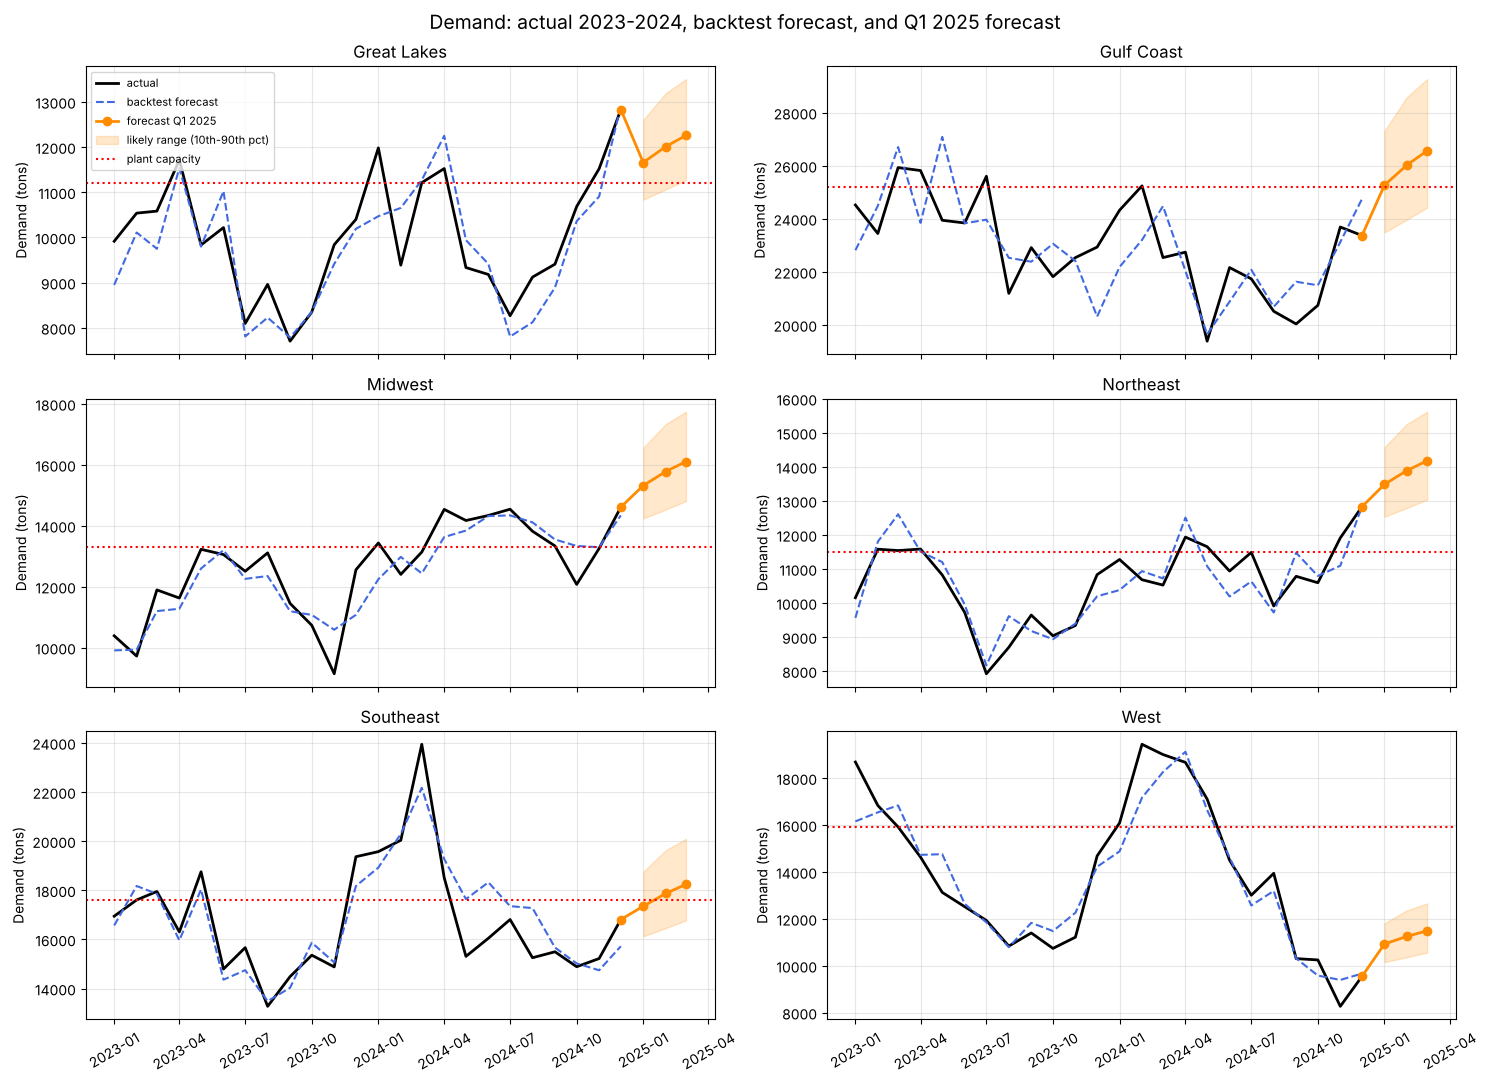

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
for ax, region in zip(axes.flat, regions):
    hist = df[(df["region"] == region) & (df["date"] >= "2023-01-01")]
    test = one_ahead[one_ahead["region"] == region].sort_values("date")
    fc = future[future["region"] == region]

    ax.plot(hist["date"], hist["demand_tons"], color="black", linewidth=2, label="actual")
    ax.plot(test["date"], test["Regression"], color="royalblue", linestyle="--", label="backtest forecast")
    ax.plot([hist["date"].iloc[-1], *fc["date"]], [hist["demand_tons"].iloc[-1], *fc["forecast_tons"]],
            color="darkorange", marker="o", linewidth=2, label="forecast Q1 2025")
    ax.fill_between(fc["date"], fc["low_tons"], fc["high_tons"], color="darkorange", alpha=0.2,
                    label="likely range (10th-90th pct)")
    ax.axhline(fc["capacity_tons"].iloc[0], color="red", linestyle=":", label="plant capacity")
    ax.set_title(region)
    ax.set_ylabel("Demand (tons)")
    ax.tick_params(axis="x", rotation=30)

axes[0, 0].legend(fontsize=8)
fig.suptitle("Demand: actual 2023-2024, backtest forecast, and Q1 2025 forecast", fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
q1 = future.groupby("region").agg(q1_forecast_tons=("forecast_tons", "sum"), q1_capacity_tons=("capacity_tons", "sum"))
q1["demand_above_capacity_tons"] = (q1["q1_forecast_tons"] - q1["q1_capacity_tons"]).clip(lower=0)
print(q1.round().astype(int).to_string())

future.to_csv("data/forecast_Q1_2025.csv", index=False)
print()
print("Saved data/forecast_Q1_2025.csv (used by the pricing notebook)")

             q1_forecast_tons  q1_capacity_tons  demand_above_capacity_tons
region                                                                     
Great Lakes             35924             33600                        2324
Gulf Coast              77853             75600                        2253
Midwest                 47202             39900                        7302
Northeast               41549             34500                        7049
Southeast               53457             52800                         657
West                    33666             47700                           0

Saved data/forecast_Q1_2025.csv (used by the pricing notebook)


**What we see (base case: Q4 2024 prices held, no promotions)**
- Demand rises from January to March in every region (seasonal peak).
- At today's prices, **Q1 demand is above plant capacity in five of six regions**:
  - Midwest by about 7,300 t
  - Northeast by about 7,000 t
  - Great Lakes by about 2,300 t
  - Gulf Coast by about 2,300 t
  - Southeast by about 700 t
- In Midwest and Northeast, even the low end of the likely range is above capacity.
- **West** is the exception (about 33,700 t against 47,700 t capacity), because its Q4 2024 price was already high (about $1,090).

**So what:** at current prices we would turn customers away in most regions. That is a strong signal that prices are too low there, which the pricing notebook will quantify. The forecast is saved to `data/forecast_Q1_2025.csv` for that step.

## 8. Summary

| Topic | Result |
|---|---|
| Features | log demand, log price, promo, log competitor price, log industrial index, region, month (sin/cos for ARIMAX), lags for baselines |
| Left out | Time trend: 0.90 correlated with the industrial index, which explains growth with a real driver |
| Chosen model | One log-linear regression across all regions, with region and month effects |
| Accuracy (backtest 2023-24) | **5.1% WAPE**, vs 7.4% ARIMAX, 11.4% same as last month, 13.8% same month last year |
| Stability | 4.8% -> 5.4% from 1 to 3 months ahead; 4.9-5.3% in every region; bias -0.8% |
| Model checks | All drivers significant; residuals random, close to normal, little autocorrelation |
| Key driver | Price elasticity **-2.06**: +1% price -> about -2.1% demand |
| Q1 2025 at today's prices | Demand above capacity in 5 of 6 regions -> prices likely too low |

**Next:** notebook 03 - price sensitivity (elasticity) in depth, then notebook 04 - pricing recommendation.